# Policy Gradient Methods in PyTorch

This notebook implements three policy-gradient algorithms following
Sutton and Barto:

- REINFORCE
- REINFORCE with baseline
- One-step Actor-Critic

The experiments use five Gymnasium environments: CartPole, Acrobot,
MountainCar, FrozenLake, and Blackjack. Each policy is represented by
a neural network.

The implementation is first developed and tested on CartPole, then
generalized to the remaining environments through observation encoding
and automatic network dimension selection.

The main experiments compare episode total rewards averaged across
five independent training runs. Preliminary learning-rate experiments
and a supplementary training-budget experiment are reported separately.

In [1]:
%pip install -q gymnasium torch numpy matplotlib


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Initial Environment Inspection

Create each of the five environments and inspect its observation
and action spaces.

For each environment, reset the initial state and execute one randomly
sampled action to verify the interaction interface. This check does
not train a policy.

Print the Gymnasium and PyTorch versions used for the experiments.

In [2]:
import gymnasium as gym
import torch

ENV_IDS = [
    "CartPole-v1",
    "Acrobot-v1",
    "MountainCar-v0",
    "FrozenLake-v1",
    "Blackjack-v1",
]

print("Gymnasium:", gym.__version__)
print("PyTorch:", torch.__version__)

for env_id in ENV_IDS:
    env = gym.make(env_id)

    state, info = env.reset(seed=0)
    env.action_space.seed(0)

    action = env.action_space.sample()
    next_state, reward, terminated, truncated, info = env.step(action)

    print(f"\n{env_id}")
    print("Observation space:", env.observation_space)
    print("Action space:", env.action_space)
    print("One-step reward:", reward)

    env.close()

Gymnasium: 1.4.0
PyTorch: 2.15.0

CartPole-v1
Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
One-step reward: 1.0

Acrobot-v1
Observation space: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Action space: Discrete(3)
One-step reward: -1.0

MountainCar-v0
Observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)
One-step reward: -1.0

FrozenLake-v1
Observation space: Discrete(16)
Action space: Discrete(4)
One-step reward: 0

Blackjack-v1
Observation space: Tuple(Discrete(32), Discrete(11), Discrete(2))
Action space: Discrete(2)
One-step reward: 0.0


## CartPole Policy Network

Begin with CartPole, whose observation contains four numerical features
and whose action space contains two discrete actions.

The policy network has the following architecture:

- Input layer: 4 features
- Hidden layer: 64 units with Tanh activation
- Output layer: 2 action logits

A categorical distribution converts the logits into action probabilities.
The policy samples actions from this distribution during training.

In [3]:
import torch
from torch import nn
from torch.distributions import Categorical

torch.manual_seed(0)


class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
        )

    def forward(self, state):
        return self.net(state)


policy = PolicyNetwork(state_dim=4, action_dim=2)
print(policy)

PolicyNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)


## Sampling an Action from the Policy

Reset CartPole and convert its initial observation into a floating-point
tensor. Pass the tensor through the policy network and construct a
categorical action distribution.

Sample one action, record its log probability, and execute it in the
environment. The log probability illustrates the quantity used in
subsequent policy-gradient updates.

The network is untrained at this stage. This example checks action
sampling and environment interaction.

In [4]:
import gymnasium as gym

env = gym.make("CartPole-v1")
state, info = env.reset(seed=0)

# Convert the observation to a floating-point tensor.
state_tensor = torch.as_tensor(state, dtype=torch.float32)

# Compute action logits and construct a categorical distribution.
logits = policy(state_tensor)
distribution = Categorical(logits=logits)

# Sample an action and record its log probability.
action = distribution.sample()
log_prob = distribution.log_prob(action)

# Convert the action to a Python integer for the environment.
next_state, reward, terminated, truncated, info = env.step(action.item())

print("State:", state)
print("Action probabilities:", distribution.probs.detach().numpy())
print("Selected action:", action.item())
print("Log probability:", log_prob.item())
print("Reward:", reward)

env.close()

State: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Action probabilities: [0.4956294  0.50437057]
Selected action: 0
Log probability: -0.7019267082214355
Reward: 1.0


## REINFORCE: Episode Collection and Returns

Collect an episode by sampling actions from the current policy until
the environment terminates or reaches its time limit.

For this experiment, the time limit defines the end of the finite episode.
No rewards beyond that boundary are included.

For each time step, compute the discounted return:

$$
G_t = \sum_{k=t}^{T-1} \gamma^{k-t} R_{k+1}.
$$

Compute returns backward using:

$$
G_t = R_{t+1} + \gamma G_{t+1}, \qquad G_T = 0.
$$

Retain the computation graph of each action's log probability for
the subsequent policy update.

In [5]:
def collect_episode(env, policy, seed=None):
    state, info = env.reset(seed=seed)

    states = []
    actions = []
    rewards = []
    log_probs = []

    while True:
        state_tensor = torch.as_tensor(state, dtype=torch.float32)

        logits = policy(state_tensor)
        distribution = Categorical(logits=logits)

        action = distribution.sample()
        log_prob = distribution.log_prob(action)

        next_state, reward, terminated, truncated, info = env.step(
            action.item()
        )

        states.append(state_tensor)
        actions.append(action.item())
        rewards.append(float(reward))
        log_probs.append(log_prob)

        state = next_state

        if terminated or truncated:
            break

    return {
        "states": states,
        "actions": actions,
        "rewards": rewards,
        "log_probs": log_probs,
        "terminated": terminated,
        "truncated": truncated,
    }

In [6]:
def compute_returns(rewards, gamma=0.99):
    returns = []
    G = 0.0

    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.append(G)

    returns.reverse()

    return torch.tensor(returns, dtype=torch.float32)


# Verify the calculation with a small example.
example_returns = compute_returns([1.0, 2.0, 3.0], gamma=0.5)

print("Example returns:", example_returns)

assert torch.allclose(
    example_returns,
    torch.tensor([2.75, 3.5, 3.0]),
)

Example returns: tensor([2.7500, 3.5000, 3.0000])


In [7]:
GAMMA = 0.99

env = gym.make("CartPole-v1")

try:
    episode = collect_episode(env, policy, seed=0)
finally:
    env.close()

returns = compute_returns(episode["rewards"], gamma=GAMMA)

print("Episode length:", len(episode["rewards"]))
print("Episode total reward:", sum(episode["rewards"]))
print("First five rewards:", episode["rewards"][:5])
print("First five returns:", returns[:5].tolist())
print("Terminated:", episode["terminated"])
print("Truncated:", episode["truncated"])
print(
    "Log probability retains gradients:",
    episode["log_probs"][0].requires_grad,
)

assert len(returns) == len(episode["log_probs"])
assert torch.isfinite(returns).all()

Episode length: 10
Episode total reward: 10.0
First five rewards: [1.0, 1.0, 1.0, 1.0, 1.0]
First five returns: [9.561792373657227, 8.648275375366211, 7.725530624389648, 6.7934651374816895, 5.851984977722168]
Terminated: True
Truncated: False
Log probability retains gradients: True


## REINFORCE: Policy Update

After collecting an episode, update the policy at each time step:

$$
\theta \leftarrow \theta
+ \alpha \gamma^t G_t
\nabla_\theta \log \pi_\theta(A_t \mid S_t).
$$

Implement this update using stochastic gradient descent on:

$$
L_t(\theta) = -\gamma^t G_t \log \pi_\theta(A_t \mid S_t).
$$

Returns are treated as fixed targets. Recompute each action's log
probability using the current parameters before its update, following
the sequential updates in the textbook pseudocode.

In [8]:
def reinforce_update(policy, optimizer, episode, gamma=0.99):
    returns = compute_returns(episode["rewards"], gamma)
    losses = []

    for t, (state, action, G_t) in enumerate(
        zip(episode["states"], episode["actions"], returns)
    ):
        # Recompute the log probability using the current parameters.
        logits = policy(state)
        distribution = Categorical(logits=logits)

        action_tensor = torch.tensor(action, dtype=torch.long)
        log_prob = distribution.log_prob(action_tensor)

        # Negate the objective because the optimizer minimizes the loss.
        loss = -(gamma ** t) * G_t * log_prob

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    return losses

In [9]:
POLICY_LR = 1e-3

optimizer = torch.optim.SGD(
    policy.parameters(),
    lr=POLICY_LR,
)

parameters_before = [
    parameter.detach().clone()
    for parameter in policy.parameters()
]

losses = reinforce_update(
    policy=policy,
    optimizer=optimizer,
    episode=episode,
    gamma=GAMMA,
)

parameters_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(parameters_before, policy.parameters())
)

print("Episode total reward:", sum(episode["rewards"]))
print("Number of parameter updates:", len(losses))
print("First five losses:", losses[:5])
print("Policy parameters changed:", parameters_changed)

assert len(losses) == len(episode["rewards"])
assert parameters_changed

Episode total reward: 10.0
Number of parameter updates: 10
First five losses: [6.544510841369629, 5.592702388763428, 4.757286071777344, 5.201417446136475, 3.593838930130005]
Policy parameters changed: True


## REINFORCE Training on CartPole

Each training episode consists of:

1. Collecting a trajectory using the current policy.
2. Computing discounted returns.
3. Updating the policy using the REINFORCE update.

Start with a fresh policy and optimizer. Record the undiscounted total
reward of each episode as the performance metric.

This initial experiment uses 300 episodes and one random seed.
The final comparison will average results over independent training runs.

In [10]:
import numpy as np


def train_reinforce_cartpole(
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    seed=0,
):
    torch.manual_seed(seed)

    env = gym.make("CartPole-v1")

    # Start from a fresh policy for this training run.
    policy = PolicyNetwork(state_dim=4, action_dim=2)
    optimizer = torch.optim.SGD(
        policy.parameters(),
        lr=policy_lr,
    )

    episode_rewards = []

    try:
        for episode_index in range(num_episodes):
            episode = collect_episode(
                env=env,
                policy=policy,
                seed=seed + episode_index,
            )

            reinforce_update(
                policy=policy,
                optimizer=optimizer,
                episode=episode,
                gamma=gamma,
            )

            total_reward = sum(episode["rewards"])
            episode_rewards.append(total_reward)

            if (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )
    finally:
        env.close()

    return policy, np.asarray(episode_rewards, dtype=np.float32)

In [11]:
reinforce_policy, reinforce_rewards = train_reinforce_cartpole(
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    seed=0,
)

print("\nTraining complete.")
print("Recorded episodes:", len(reinforce_rewards))
print(
    "Mean reward over first 50 episodes:",
    f"{reinforce_rewards[:50].mean():.2f}",
)
print(
    "Mean reward over last 50 episodes:",
    f"{reinforce_rewards[-50:].mean():.2f}",
)

Episode 50/300 | Mean reward over last 50 episodes: 35.76
Episode 100/300 | Mean reward over last 50 episodes: 90.88
Episode 150/300 | Mean reward over last 50 episodes: 66.98
Episode 200/300 | Mean reward over last 50 episodes: 90.76
Episode 250/300 | Mean reward over last 50 episodes: 126.64
Episode 300/300 | Mean reward over last 50 episodes: 160.56

Training complete.
Recorded episodes: 300
Mean reward over first 50 episodes: 35.76
Mean reward over last 50 episodes: 160.56


## REINFORCE with Baseline: Value Network

Use a separate neural network to estimate the state value:

$$
\hat v(S_t,w) \approx \mathbb{E}_{\pi}[G_t \mid S_t].
$$

The policy update uses the return minus the state-value baseline:

$$
\delta_t = G_t - \hat v(S_t,w).
$$

The baseline depends on the state, not the sampled action.
It is intended to reduce the variance of the policy-gradient estimate.

This algorithm still uses complete sampled returns. The value network
will be trained toward those returns.

In [12]:
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

    def forward(self, state):
        return self.net(state).squeeze(-1)


torch.manual_seed(0)

# Initialize a fresh policy and a separate value network.
baseline_policy = PolicyNetwork(state_dim=4, action_dim=2)
baseline_value = ValueNetwork(state_dim=4)

print(baseline_value)

ValueNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [13]:
env = gym.make("CartPole-v1")

try:
    baseline_episode = collect_episode(
        env=env,
        policy=baseline_policy,
        seed=0,
    )
finally:
    env.close()

baseline_returns = compute_returns(
    baseline_episode["rewards"],
    gamma=0.99,
)

state_batch = torch.stack(baseline_episode["states"])
value_estimates = baseline_value(state_batch)

# Treat the baseline as fixed when forming the policy-update signal.
advantages = baseline_returns - value_estimates.detach()

print("Episode length:", len(baseline_episode["rewards"]))
print("First five returns:", baseline_returns[:5].tolist())
print(
    "First five value estimates:",
    value_estimates[:5].detach().tolist(),
)
print("First five advantages:", advantages[:5].tolist())
print("Value estimate shape:", tuple(value_estimates.shape))
print("Return shape:", tuple(baseline_returns.shape))

assert value_estimates.shape == baseline_returns.shape
assert torch.isfinite(advantages).all()

Episode length: 14
First five returns: [13.125418663024902, 12.24789810180664, 11.361513137817383, 10.466174125671387, 9.561792373657227]
First five value estimates: [0.043413594365119934, -0.07193481922149658, 0.03698204457759857, -0.07915513217449188, -0.1938970386981964]
First five advantages: [13.082005500793457, 12.319832801818848, 11.324531555175781, 10.545329093933105, 9.75568962097168]
Value estimate shape: (14,)
Return shape: (14,)


## REINFORCE with Baseline: Parameter Updates

For each time step, compute the return minus the current value estimate:

$$
\delta_t = G_t - \hat v(S_t,w).
$$

Update the value network by minimizing:

$$
L_v(w) = \frac{1}{2}\left(G_t-\hat v(S_t,w)\right)^2.
$$

Update the policy by minimizing:

$$
L_\pi(\theta) =
-\gamma^t \operatorname{stopgrad}(\delta_t)
\log\pi_\theta(A_t\mid S_t).
$$

Both updates use the same residual computed before either update.
The policy loss does not propagate gradients into the value network.
Use separate SGD optimizers for the two networks.

In [14]:
def reinforce_baseline_update(
    policy,
    value_network,
    policy_optimizer,
    value_optimizer,
    episode,
    gamma=0.99,
):
    returns = compute_returns(episode["rewards"], gamma)

    policy_losses = []
    value_losses = []

    for t, (state, action, G_t) in enumerate(
        zip(episode["states"], episode["actions"], returns)
    ):
        # Compute the residual before updating either network.
        value = value_network(state)
        residual = G_t - value
        policy_signal = residual.detach()

        # Update the value network toward the sampled return.
        value_loss = 0.5 * residual.square()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        # Recompute the action log probability with the current policy.
        logits = policy(state)
        distribution = Categorical(logits=logits)
        action_tensor = torch.tensor(action, dtype=torch.long)
        log_prob = distribution.log_prob(action_tensor)

        # Update only the policy network through this loss.
        policy_loss = -(gamma ** t) * policy_signal * log_prob

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        policy_losses.append(policy_loss.item())
        value_losses.append(value_loss.item())

    return {
        "policy_losses": policy_losses,
        "value_losses": value_losses,
    }

In [15]:
baseline_policy_optimizer = torch.optim.SGD(
    baseline_policy.parameters(),
    lr=1e-3,
)

baseline_value_optimizer = torch.optim.SGD(
    baseline_value.parameters(),
    lr=1e-3,
)

policy_before = [
    parameter.detach().clone()
    for parameter in baseline_policy.parameters()
]

value_before = [
    parameter.detach().clone()
    for parameter in baseline_value.parameters()
]

baseline_losses = reinforce_baseline_update(
    policy=baseline_policy,
    value_network=baseline_value,
    policy_optimizer=baseline_policy_optimizer,
    value_optimizer=baseline_value_optimizer,
    episode=baseline_episode,
    gamma=0.99,
)

policy_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(policy_before, baseline_policy.parameters())
)

value_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(value_before, baseline_value.parameters())
)

print("Policy updates:", len(baseline_losses["policy_losses"]))
print("Value updates:", len(baseline_losses["value_losses"]))
print("Policy parameters changed:", policy_changed)
print("Value parameters changed:", value_changed)

assert policy_changed
assert value_changed

Policy updates: 14
Value updates: 14
Policy parameters changed: True
Value parameters changed: True


## REINFORCE with Baseline Training on CartPole

Initialize a fresh policy network and value network, each with its own
SGD optimizer.

For each episode:

1. Collect a trajectory using the current policy.
2. Compute discounted returns.
3. Update the value network and policy using REINFORCE with baseline.
4. Record the undiscounted episode total reward.

Use the same episode count, discount factor, policy learning rate,
and seed as the initial REINFORCE experiment. The value learning rate
is set separately.

In [16]:
def train_reinforce_baseline_cartpole(
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    value_lr=1e-3,
    seed=0,
):
    torch.manual_seed(seed)

    env = gym.make("CartPole-v1")

    # Initialize fresh networks for this independent training run.
    policy = PolicyNetwork(state_dim=4, action_dim=2)
    value_network = ValueNetwork(state_dim=4)

    policy_optimizer = torch.optim.SGD(
        policy.parameters(),
        lr=policy_lr,
    )
    value_optimizer = torch.optim.SGD(
        value_network.parameters(),
        lr=value_lr,
    )

    episode_rewards = []

    try:
        for episode_index in range(num_episodes):
            episode = collect_episode(
                env=env,
                policy=policy,
                seed=seed + episode_index,
            )

            reinforce_baseline_update(
                policy=policy,
                value_network=value_network,
                policy_optimizer=policy_optimizer,
                value_optimizer=value_optimizer,
                episode=episode,
                gamma=gamma,
            )

            total_reward = sum(episode["rewards"])
            episode_rewards.append(total_reward)

            if (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )
    finally:
        env.close()

    return (
        policy,
        value_network,
        np.asarray(episode_rewards, dtype=np.float32),
    )

In [17]:
(
    trained_baseline_policy,
    trained_baseline_value,
    baseline_rewards,
) = train_reinforce_baseline_cartpole(
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    value_lr=1e-3,
    seed=0,
)

print("\nTraining complete.")
print("Recorded episodes:", len(baseline_rewards))
print(
    "Mean reward over first 50 episodes:",
    f"{baseline_rewards[:50].mean():.2f}",
)
print(
    "Mean reward over last 50 episodes:",
    f"{baseline_rewards[-50:].mean():.2f}",
)

Episode 50/300 | Mean reward over last 50 episodes: 45.22
Episode 100/300 | Mean reward over last 50 episodes: 65.00
Episode 150/300 | Mean reward over last 50 episodes: 94.36
Episode 200/300 | Mean reward over last 50 episodes: 290.60
Episode 250/300 | Mean reward over last 50 episodes: 110.64
Episode 300/300 | Mean reward over last 50 episodes: 21.80

Training complete.
Recorded episodes: 300
Mean reward over first 50 episodes: 45.22
Mean reward over last 50 episodes: 21.80


### Learning Rate Check

With a policy learning rate of 0.001, the mean reward reached 290.60
during episodes 151–200, then fell to 21.80 during episodes 251–300.

This run shows substantial performance deterioration after an initial
improvement. A large policy update step may contribute to instability,
although episode rewards alone do not establish the cause.

Repeat the experiment with a policy learning rate of 0.0001.
Keep the value learning rate, episode count, discount factor, and seed
unchanged. Retain both runs for comparison.

In [18]:
(
    baseline_policy_small_lr,
    baseline_value_small_lr,
    baseline_rewards_small_lr,
) = train_reinforce_baseline_cartpole(
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-4,
    value_lr=1e-3,
    seed=0,
)

print("\nMean reward over the last 50 episodes:")
print(f"Policy LR = 0.001:  {baseline_rewards[-50:].mean():.2f}")
print(f"Policy LR = 0.0001: {baseline_rewards_small_lr[-50:].mean():.2f}")

Episode 50/300 | Mean reward over last 50 episodes: 29.08
Episode 100/300 | Mean reward over last 50 episodes: 29.14
Episode 150/300 | Mean reward over last 50 episodes: 34.60
Episode 200/300 | Mean reward over last 50 episodes: 40.32
Episode 250/300 | Mean reward over last 50 episodes: 57.02
Episode 300/300 | Mean reward over last 50 episodes: 53.76

Mean reward over the last 50 episodes:
Policy LR = 0.001:  21.80
Policy LR = 0.0001: 53.76


## One-Step Actor-Critic: TD Target and TD Error

The actor represents the policy, and the critic estimates the state value.

After each transition, compute the TD target:

$$
Y_t =
\begin{cases}
R_{t+1}, & \text{if the episode ends},\\
R_{t+1} + \gamma \hat v(S_{t+1},w), & \text{otherwise}.
\end{cases}
$$

The TD error is:

$$
\delta_t = Y_t - \hat v(S_t,w).
$$

Unlike REINFORCE with baseline, this method bootstraps from the next
state's estimated value instead of waiting for a complete sampled return.

Consistent with the preceding experiments, the environment's time limit
defines the end of the finite episode. Both termination and truncation
therefore use zero subsequent value.

Treat the TD target as fixed when computing the critic's gradient.

In [19]:
torch.manual_seed(0)

actor = PolicyNetwork(state_dim=4, action_dim=2)
critic = ValueNetwork(state_dim=4)

print("Actor:")
print(actor)

print("\nCritic:")
print(critic)

Actor:
PolicyNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)

Critic:
ValueNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [20]:
AC_GAMMA = 0.99

env = gym.make("CartPole-v1")

try:
    state, info = env.reset(seed=0)
    ac_state = torch.as_tensor(state, dtype=torch.float32)

    # Sample an action from the actor.
    ac_distribution = Categorical(logits=actor(ac_state))
    ac_action = ac_distribution.sample()
    ac_log_prob = ac_distribution.log_prob(ac_action)

    next_state, reward, terminated, truncated, info = env.step(
        ac_action.item()
    )

    ac_next_state = torch.as_tensor(
        next_state,
        dtype=torch.float32,
    )
    episode_ended = terminated or truncated

    # Estimate the current state's value.
    ac_value = critic(ac_state)

    # Construct a fixed TD target without tracking its gradients.
    with torch.no_grad():
        if episode_ended:
            ac_next_value = torch.tensor(0.0)
        else:
            ac_next_value = critic(ac_next_state)

        ac_td_target = reward + AC_GAMMA * ac_next_value

    ac_td_error = ac_td_target - ac_value

    print("Reward:", reward)
    print("Current state value:", ac_value.item())
    print("Next state value:", ac_next_value.item())
    print("TD target:", ac_td_target.item())
    print("TD error:", ac_td_error.item())
    print("Episode ended:", episode_ended)
    print("TD target requires gradients:", ac_td_target.requires_grad)
    print("Current value requires gradients:", ac_value.requires_grad)

finally:
    env.close()

Reward: 1.0
Current state value: 0.04341357946395874
Next state value: -0.07193482667207718
TD target: 0.9287844896316528
TD error: 0.8853709101676941
Episode ended: False
TD target requires gradients: False
Current value requires gradients: True


## One-Step Actor-Critic: Parameter Updates

Compute the TD error before updating either network.

The critic minimizes the squared TD error using a fixed target:

$$
L_v(w)=\frac{1}{2}\left(Y_t-\hat v(S_t,w)\right)^2.
$$

The actor minimizes:

$$
L_\pi(\theta)=
-I_t\operatorname{stopgrad}(\delta_t)
\log\pi_\theta(A_t\mid S_t).
$$

Initialize the discount weight to 1 at the start of each episode.
After each transition, multiply it by the discount factor:

$$
I_0=1,\qquad I_{t+1}=\gamma I_t.
$$

Update both networks immediately after each transition.

In [21]:
def actor_critic_update(
    actor,
    critic,
    actor_optimizer,
    critic_optimizer,
    state,
    action,
    reward,
    next_state,
    episode_ended,
    discount_weight=1.0,
    gamma=0.99,
):
    value = critic(state)

    # Construct the fixed bootstrap target.
    with torch.no_grad():
        if episode_ended:
            next_value = torch.zeros_like(value)
        else:
            next_value = critic(next_state)

        td_target = reward + gamma * next_value

    # Use the same pre-update TD error for both networks.
    td_error = td_target - value
    actor_signal = td_error.detach()

    critic_loss = 0.5 * td_error.square()

    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    # Compute the actor's loss using the sampled action.
    distribution = Categorical(logits=actor(state))
    action_tensor = torch.as_tensor(action, dtype=torch.long)
    log_prob = distribution.log_prob(action_tensor)

    actor_loss = -discount_weight * actor_signal * log_prob

    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    return {
        "td_error": td_error.item(),
        "actor_loss": actor_loss.item(),
        "critic_loss": critic_loss.item(),
    }

In [22]:
actor_optimizer = torch.optim.SGD(
    actor.parameters(),
    lr=1e-3,
)

critic_optimizer = torch.optim.SGD(
    critic.parameters(),
    lr=1e-3,
)

actor_before = [
    parameter.detach().clone()
    for parameter in actor.parameters()
]
critic_before = [
    parameter.detach().clone()
    for parameter in critic.parameters()
]

update_result = actor_critic_update(
    actor=actor,
    critic=critic,
    actor_optimizer=actor_optimizer,
    critic_optimizer=critic_optimizer,
    state=ac_state,
    action=ac_action.item(),
    reward=reward,
    next_state=ac_next_state,
    episode_ended=episode_ended,
    discount_weight=1.0,
    gamma=AC_GAMMA,
)

actor_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(actor_before, actor.parameters())
)
critic_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(critic_before, critic.parameters())
)

print("TD error:", update_result["td_error"])
print("Actor loss:", update_result["actor_loss"])
print("Critic loss:", update_result["critic_loss"])
print("Actor parameters changed:", actor_changed)
print("Critic parameters changed:", critic_changed)

assert actor_changed
assert critic_changed

TD error: 0.8853709101676941
Actor loss: 0.6059867739677429
Critic loss: 0.3919408321380615
Actor parameters changed: True
Critic parameters changed: True


## One-Step Actor-Critic Training on CartPole

Initialize a fresh actor and critic with separate SGD optimizers.

At the start of each episode, reset the environment and set the
discount weight to 1.

For each transition:

1. Sample an action from the current actor.
2. Execute the action in the environment.
3. Compute the TD target and TD error.
4. Update the critic and actor immediately.
5. Multiply the discount weight by gamma.

Record the undiscounted total reward of each episode.
Use 300 episodes and seed 0 for this initial experiment.

In [23]:
def train_actor_critic_cartpole(
    num_episodes=300,
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    seed=0,
):
    torch.manual_seed(seed)

    env = gym.make("CartPole-v1")

    actor = PolicyNetwork(state_dim=4, action_dim=2)
    critic = ValueNetwork(state_dim=4)

    actor_optimizer = torch.optim.SGD(
        actor.parameters(),
        lr=actor_lr,
    )
    critic_optimizer = torch.optim.SGD(
        critic.parameters(),
        lr=critic_lr,
    )

    episode_rewards = []

    try:
        for episode_index in range(num_episodes):
            state, info = env.reset(seed=seed + episode_index)
            state_tensor = torch.as_tensor(state, dtype=torch.float32)

            total_reward = 0.0
            discount_weight = 1.0

            while True:
                # Gradients are recomputed inside the update function.
                with torch.no_grad():
                    distribution = Categorical(
                        logits=actor(state_tensor)
                    )
                    action = distribution.sample().item()

                next_state, reward, terminated, truncated, info = env.step(
                    action
                )

                next_state_tensor = torch.as_tensor(
                    next_state,
                    dtype=torch.float32,
                )
                episode_ended = terminated or truncated

                actor_critic_update(
                    actor=actor,
                    critic=critic,
                    actor_optimizer=actor_optimizer,
                    critic_optimizer=critic_optimizer,
                    state=state_tensor,
                    action=action,
                    reward=reward,
                    next_state=next_state_tensor,
                    episode_ended=episode_ended,
                    discount_weight=discount_weight,
                    gamma=gamma,
                )

                total_reward += reward
                discount_weight *= gamma
                state_tensor = next_state_tensor

                if episode_ended:
                    break

            episode_rewards.append(total_reward)

            if (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )
    finally:
        env.close()

    return (
        actor,
        critic,
        np.asarray(episode_rewards, dtype=np.float32),
    )

In [24]:
(
    trained_actor,
    trained_critic,
    actor_critic_rewards,
) = train_actor_critic_cartpole(
    num_episodes=300,
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    seed=0,
)

print("\nTraining complete.")
print("Recorded episodes:", len(actor_critic_rewards))
print(
    "Mean reward over first 50 episodes:",
    f"{actor_critic_rewards[:50].mean():.2f}",
)
print(
    "Mean reward over last 50 episodes:",
    f"{actor_critic_rewards[-50:].mean():.2f}",
)

Episode 50/300 | Mean reward over last 50 episodes: 21.18
Episode 100/300 | Mean reward over last 50 episodes: 29.18
Episode 150/300 | Mean reward over last 50 episodes: 54.28
Episode 200/300 | Mean reward over last 50 episodes: 67.54
Episode 250/300 | Mean reward over last 50 episodes: 120.94
Episode 300/300 | Mean reward over last 50 episodes: 105.58

Training complete.
Recorded episodes: 300
Mean reward over first 50 episodes: 21.18
Mean reward over last 50 episodes: 105.58


## CartPole: Comparison Across Independent Runs

Compare the three algorithms over five independent training runs.

Each run starts with fresh networks and optimizers. Use seeds 1–5,
300 episodes per run, a discount factor of 0.99, and SGD optimizers.

| Algorithm | Policy learning rate | Value learning rate |
| --- | --- | --- |
| REINFORCE | 0.001 | N/A |
| REINFORCE with baseline | 0.0001 | 0.001 |
| One-step Actor-Critic | 0.001 | 0.001 |

These learning rates are fixed before running the comparison.
Seed 0 was used for preliminary experiments.

Plot the undiscounted episode total reward, averaged across runs.

In [25]:
SEEDS = [1, 2, 3, 4, 5]
NUM_EPISODES = 300

cartpole_results = {
    "REINFORCE": [],
    "REINFORCE with baseline": [],
    "One-step Actor-Critic": [],
}

for seed in SEEDS:
    print(f"\n=== REINFORCE | Seed {seed} ===")

    _, rewards = train_reinforce_cartpole(
        num_episodes=NUM_EPISODES,
        gamma=0.99,
        policy_lr=1e-3,
        seed=seed,
    )
    cartpole_results["REINFORCE"].append(rewards)

    print(f"\n=== REINFORCE with baseline | Seed {seed} ===")

    _, _, rewards = train_reinforce_baseline_cartpole(
        num_episodes=NUM_EPISODES,
        gamma=0.99,
        policy_lr=1e-4,
        value_lr=1e-3,
        seed=seed,
    )
    cartpole_results["REINFORCE with baseline"].append(rewards)

    print(f"\n=== One-step Actor-Critic | Seed {seed} ===")

    _, _, rewards = train_actor_critic_cartpole(
        num_episodes=NUM_EPISODES,
        gamma=0.99,
        actor_lr=1e-3,
        critic_lr=1e-3,
        seed=seed,
    )
    cartpole_results["One-step Actor-Critic"].append(rewards)

cartpole_results = {
    name: np.stack(runs)
    for name, runs in cartpole_results.items()
}

print("\nExperiment complete.")
for name, runs in cartpole_results.items():
    print(f"{name}: {runs.shape}")


=== REINFORCE | Seed 1 ===
Episode 50/300 | Mean reward over last 50 episodes: 62.50
Episode 100/300 | Mean reward over last 50 episodes: 59.58
Episode 150/300 | Mean reward over last 50 episodes: 55.02
Episode 200/300 | Mean reward over last 50 episodes: 51.78
Episode 250/300 | Mean reward over last 50 episodes: 53.08
Episode 300/300 | Mean reward over last 50 episodes: 164.12

=== REINFORCE with baseline | Seed 1 ===
Episode 50/300 | Mean reward over last 50 episodes: 24.92
Episode 100/300 | Mean reward over last 50 episodes: 36.94
Episode 150/300 | Mean reward over last 50 episodes: 52.62
Episode 200/300 | Mean reward over last 50 episodes: 53.86
Episode 250/300 | Mean reward over last 50 episodes: 58.64
Episode 300/300 | Mean reward over last 50 episodes: 54.48

=== One-step Actor-Critic | Seed 1 ===
Episode 50/300 | Mean reward over last 50 episodes: 20.50
Episode 100/300 | Mean reward over last 50 episodes: 14.50
Episode 150/300 | Mean reward over last 50 episodes: 31.88
Episode

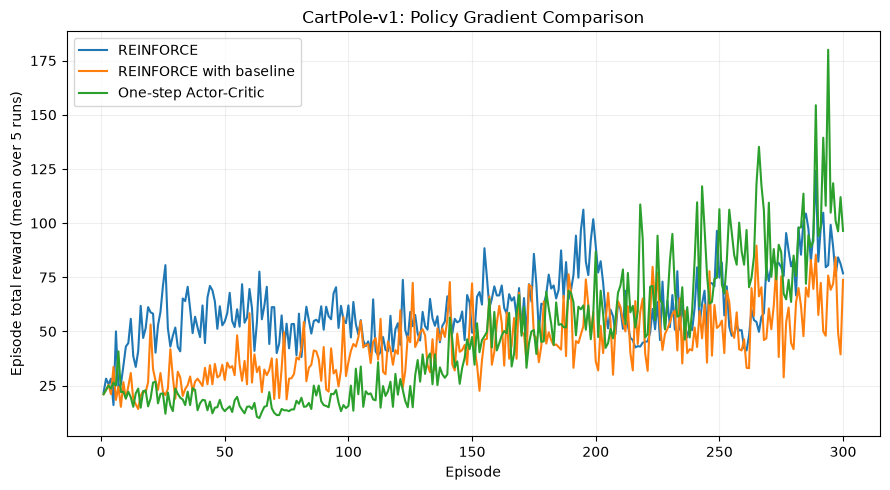

In [26]:
import matplotlib.pyplot as plt

episodes = np.arange(1, NUM_EPISODES + 1)

fig, ax = plt.subplots(figsize=(9, 5))

for name, runs in cartpole_results.items():
    mean_rewards = runs.mean(axis=0)
    ax.plot(episodes, mean_rewards, label=name)

ax.set_title("CartPole-v1: Policy Gradient Comparison")
ax.set_xlabel("Episode")
ax.set_ylabel(f"Episode total reward (mean over {len(SEEDS)} runs)")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

In [27]:
print("Final 50-episode mean reward for each seed:\n")

for name, runs in cartpole_results.items():
    final_means = runs[:, -50:].mean(axis=1)

    print(name)
    print("Seeds:", SEEDS)
    print("Per-seed means:", np.round(final_means, 2))
    print(f"Mean across seeds: {final_means.mean():.2f}")
    print()

Final 50-episode mean reward for each seed:

REINFORCE
Seeds: [1, 2, 3, 4, 5]
Per-seed means: [164.12  58.64  61.22  44.7   47.84]
Mean across seeds: 75.30

REINFORCE with baseline
Seeds: [1, 2, 3, 4, 5]
Per-seed means: [54.48 57.56 58.74 51.54 70.86]
Mean across seeds: 58.64

One-step Actor-Critic
Seeds: [1, 2, 3, 4, 5]
Per-seed means: [100.3  102.18  91.64  85.66  94.94]
Mean across seeds: 94.94



### CartPole Results

Over the final 50 episodes, the mean rewards across five runs were:

- REINFORCE: 75.30
- REINFORCE with baseline: 58.64
- One-step Actor-Critic: 94.94

One-step Actor-Critic achieved the highest final-window mean reward
under the tested configurations. REINFORCE showed substantial variation
between seeds, with final-window means ranging from 44.70 to 164.12.

The baseline variant improved more slowly and obtained the lowest
final-window mean reward in this experiment.

These results describe the selected architectures, learning rates,
training budget, and seeds. They do not establish a general ranking
of the algorithms.

## Observation Encoding for Five Environments

Convert each observation into a one-dimensional floating-point tensor
using Gymnasium's observation-space utilities.

Box observations are flattened directly. Discrete observations are
one-hot encoded. Tuple observations are flattened by encoding and
concatenating their components.

Determine the policy and value network input dimensions from the
encoded observation space. All five environments have discrete actions.

In [28]:
from gymnasium.spaces.utils import flatdim, flatten


def encode_state(state, observation_space):
    encoded = flatten(observation_space, state)
    return torch.as_tensor(encoded, dtype=torch.float32)

In [29]:
ENV_IDS = [
    "CartPole-v1",
    "Acrobot-v1",
    "MountainCar-v0",
    "FrozenLake-v1",
    "Blackjack-v1",
]

for env_id in ENV_IDS:
    env = gym.make(env_id)

    try:
        state, info = env.reset(seed=0)

        encoded_state = encode_state(
            state,
            env.observation_space,
        )
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        print(
            f"{env_id}: "
            f"state_dim={state_dim}, "
            f"action_dim={action_dim}, "
            f"encoded_shape={tuple(encoded_state.shape)}"
        )

        assert encoded_state.shape == (state_dim,)
        assert torch.isfinite(encoded_state).all()

    finally:
        env.close()

CartPole-v1: state_dim=4, action_dim=2, encoded_shape=(4,)
Acrobot-v1: state_dim=6, action_dim=3, encoded_shape=(6,)
MountainCar-v0: state_dim=2, action_dim=3, encoded_shape=(2,)
FrozenLake-v1: state_dim=16, action_dim=4, encoded_shape=(16,)
Blackjack-v1: state_dim=45, action_dim=2, encoded_shape=(45,)


## Episode Collection Across Environments

Collect a complete episode using the current policy.

Encode each observation according to its observation space before
passing it to the policy network. Store the encoded states, sampled
actions, rewards, and action log probabilities.

Collection stops when the environment terminates or reaches its time
limit. The caller creates and closes the environment.

This function is used by REINFORCE and REINFORCE with baseline.
One-step Actor-Critic performs updates during environment interaction
and therefore uses a separate interaction loop.

In [30]:
from torch.distributions import Categorical


def collect_episode_general(env, policy, seed=None):
    state, info = env.reset(seed=seed)

    states = []
    actions = []
    rewards = []
    log_probs = []

    while True:
        # Encode the observation using its environment-specific space.
        state_tensor = encode_state(
            state,
            env.observation_space,
        )

        logits = policy(state_tensor)
        distribution = Categorical(logits=logits)

        action = distribution.sample()
        log_prob = distribution.log_prob(action)

        next_state, reward, terminated, truncated, info = env.step(
            action.item()
        )

        states.append(state_tensor)
        actions.append(action.item())
        rewards.append(float(reward))
        log_probs.append(log_prob)

        state = next_state

        if terminated or truncated:
            break

    return {
        "states": states,
        "actions": actions,
        "rewards": rewards,
        "log_probs": log_probs,
        "terminated": terminated,
        "truncated": truncated,
    }

In [31]:
torch.manual_seed(0)

for env_id in ENV_IDS:
    env = gym.make(env_id)

    try:
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        test_policy = PolicyNetwork(
            state_dim=state_dim,
            action_dim=action_dim,
        )

        episode = collect_episode_general(
            env=env,
            policy=test_policy,
            seed=0,
        )

        episode_length = len(episode["rewards"])
        total_reward = sum(episode["rewards"])

        assert (
            len(episode["states"])
            == len(episode["actions"])
            == len(episode["rewards"])
            == len(episode["log_probs"])
        )
        assert episode["states"][0].shape == (state_dim,)
        assert episode["terminated"] or episode["truncated"]

        print(
            f"{env_id}: "
            f"steps={episode_length}, "
            f"total_reward={total_reward:.2f}, "
            f"state_shape={tuple(episode['states'][0].shape)}"
        )

    finally:
        env.close()

CartPole-v1: steps=14, total_reward=14.00, state_shape=(4,)
Acrobot-v1: steps=500, total_reward=-500.00, state_shape=(6,)
MountainCar-v0: steps=200, total_reward=-200.00, state_shape=(2,)
FrozenLake-v1: steps=15, total_reward=0.00, state_shape=(16,)
Blackjack-v1: steps=1, total_reward=-1.00, state_shape=(45,)


## REINFORCE Training Across Environments

Use a shared training function for all five environments.

Determine the policy input dimension from the flattened observation
space and the output dimension from the discrete action space.

Each run initializes a fresh policy and SGD optimizer. Collect a complete
episode, apply the REINFORCE updates, and record its undiscounted total
reward.

Use the same hidden-layer architecture with 64 units across environments.

In [32]:
import numpy as np


def train_reinforce(
    env_id,
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    seed=0,
    verbose=True,
):
    torch.manual_seed(seed)

    env = gym.make(env_id)

    try:
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        policy = PolicyNetwork(
            state_dim=state_dim,
            action_dim=action_dim,
        )
        optimizer = torch.optim.SGD(
            policy.parameters(),
            lr=policy_lr,
        )

        episode_rewards = []

        for episode_index in range(num_episodes):
            episode = collect_episode_general(
                env=env,
                policy=policy,
                seed=seed + episode_index,
            )

            reinforce_update(
                policy=policy,
                optimizer=optimizer,
                episode=episode,
                gamma=gamma,
            )

            total_reward = sum(episode["rewards"])
            episode_rewards.append(total_reward)

            if verbose and (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"{env_id} | REINFORCE | "
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )

    finally:
        env.close()

    return policy, np.asarray(episode_rewards, dtype=np.float32)

In [33]:
for env_id in ENV_IDS:
    _, check_rewards = train_reinforce(
        env_id=env_id,
        num_episodes=3,
        gamma=0.99,
        policy_lr=1e-3,
        seed=0,
        verbose=False,
    )

    assert check_rewards.shape == (3,)
    assert np.isfinite(check_rewards).all()

    print(f"{env_id}: rewards={check_rewards.tolist()}")

CartPole-v1: rewards=[14.0, 13.0, 22.0]
Acrobot-v1: rewards=[-500.0, -500.0, -500.0]
MountainCar-v0: rewards=[-200.0, -200.0, -200.0]
FrozenLake-v1: rewards=[0.0, 0.0, 0.0]
Blackjack-v1: rewards=[-1.0, -1.0, -1.0]


## REINFORCE with Baseline Training Across Environments

Use a shared training function for all five environments.

Initialize a fresh policy network and value network with input dimensions
determined by the encoded observation space. Use separate SGD optimizers.

For each episode, collect a complete trajectory, compute sampled returns,
and update both networks using REINFORCE with baseline.

Record the undiscounted episode total reward. Learning rates are explicit
function arguments and will be recorded for each experiment.

In [34]:
def train_reinforce_baseline(
    env_id,
    num_episodes=300,
    gamma=0.99,
    policy_lr=1e-4,
    value_lr=1e-3,
    seed=0,
    verbose=True,
):
    torch.manual_seed(seed)

    env = gym.make(env_id)

    try:
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        policy = PolicyNetwork(
            state_dim=state_dim,
            action_dim=action_dim,
        )
        value_network = ValueNetwork(state_dim=state_dim)

        policy_optimizer = torch.optim.SGD(
            policy.parameters(),
            lr=policy_lr,
        )
        value_optimizer = torch.optim.SGD(
            value_network.parameters(),
            lr=value_lr,
        )

        episode_rewards = []

        for episode_index in range(num_episodes):
            episode = collect_episode_general(
                env=env,
                policy=policy,
                seed=seed + episode_index,
            )

            reinforce_baseline_update(
                policy=policy,
                value_network=value_network,
                policy_optimizer=policy_optimizer,
                value_optimizer=value_optimizer,
                episode=episode,
                gamma=gamma,
            )

            total_reward = sum(episode["rewards"])
            episode_rewards.append(total_reward)

            if verbose and (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"{env_id} | REINFORCE with baseline | "
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )

    finally:
        env.close()

    return (
        policy,
        value_network,
        np.asarray(episode_rewards, dtype=np.float32),
    )

In [35]:
for env_id in ENV_IDS:
    _, _, check_rewards = train_reinforce_baseline(
        env_id=env_id,
        num_episodes=3,
        gamma=0.99,
        policy_lr=1e-4,
        value_lr=1e-3,
        seed=0,
        verbose=False,
    )

    assert check_rewards.shape == (3,)
    assert np.isfinite(check_rewards).all()

    print(f"{env_id}: rewards={check_rewards.tolist()}")

CartPole-v1: rewards=[14.0, 25.0, 12.0]
Acrobot-v1: rewards=[-500.0, -500.0, -500.0]
MountainCar-v0: rewards=[-200.0, -200.0, -200.0]
FrozenLake-v1: rewards=[0.0, 0.0, 0.0]
Blackjack-v1: rewards=[-1.0, -1.0, -1.0]


## One-Step Actor-Critic Training Across Environments

Initialize a fresh actor and critic for each training run.
Determine their dimensions from the observation and action spaces.

Encode both the current and next observations before computing values
and policy outputs. Update both networks immediately after each
transition.

Reset the discount weight to 1 at the start of each episode and multiply
it by gamma after each update.

Treat termination and truncation as the end of the finite episode,
consistent with the preceding experiments. Record undiscounted episode
total rewards.

In [36]:
def train_actor_critic(
    env_id,
    num_episodes=300,
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    seed=0,
    verbose=True,
):
    torch.manual_seed(seed)
    env = gym.make(env_id)

    try:
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        actor = PolicyNetwork(
            state_dim=state_dim,
            action_dim=action_dim,
        )
        critic = ValueNetwork(state_dim=state_dim)

        actor_optimizer = torch.optim.SGD(
            actor.parameters(),
            lr=actor_lr,
        )
        critic_optimizer = torch.optim.SGD(
            critic.parameters(),
            lr=critic_lr,
        )

        episode_rewards = []

        for episode_index in range(num_episodes):
            state, info = env.reset(seed=seed + episode_index)
            state_tensor = encode_state(state, env.observation_space)

            total_reward = 0.0
            discount_weight = 1.0

            while True:
                # The update function recomputes policy gradients.
                with torch.no_grad():
                    distribution = Categorical(
                        logits=actor(state_tensor)
                    )
                    action = distribution.sample().item()

                next_state, reward, terminated, truncated, info = env.step(
                    action
                )

                next_state_tensor = encode_state(
                    next_state,
                    env.observation_space,
                )
                episode_ended = terminated or truncated

                actor_critic_update(
                    actor=actor,
                    critic=critic,
                    actor_optimizer=actor_optimizer,
                    critic_optimizer=critic_optimizer,
                    state=state_tensor,
                    action=action,
                    reward=reward,
                    next_state=next_state_tensor,
                    episode_ended=episode_ended,
                    discount_weight=discount_weight,
                    gamma=gamma,
                )

                total_reward += reward
                discount_weight *= gamma
                state_tensor = next_state_tensor

                if episode_ended:
                    break

            episode_rewards.append(total_reward)

            if verbose and (episode_index + 1) % 50 == 0:
                recent_mean = np.mean(episode_rewards[-50:])
                print(
                    f"{env_id} | One-step Actor-Critic | "
                    f"Episode {episode_index + 1}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )

    finally:
        env.close()

    return (
        actor,
        critic,
        np.asarray(episode_rewards, dtype=np.float32),
    )

In [37]:
for env_id in ENV_IDS:
    _, _, check_rewards = train_actor_critic(
        env_id=env_id,
        num_episodes=3,
        gamma=0.99,
        actor_lr=1e-3,
        critic_lr=1e-3,
        seed=0,
        verbose=False,
    )

    assert check_rewards.shape == (3,)
    assert np.isfinite(check_rewards).all()

    print(f"{env_id}: rewards={check_rewards.tolist()}")

CartPole-v1: rewards=[14.0, 25.0, 12.0]
Acrobot-v1: rewards=[-500.0, -500.0, -500.0]
MountainCar-v0: rewards=[-200.0, -200.0, -200.0]
FrozenLake-v1: rewards=[0.0, 0.0, 0.0]
Blackjack-v1: rewards=[-1.0, -1.0, -1.0]


## Experiments Across Environments

Run each algorithm with seeds 1–5 and 300 episodes per seed.
Use a discount factor of 0.99 and fresh networks and optimizers
for every run.

All networks use one hidden layer with 64 Tanh units.
Input and output dimensions depend on the environment.

| Algorithm | Policy learning rate | Value learning rate |
| --- | --- | --- |
| REINFORCE | 0.001 | N/A |
| REINFORCE with baseline | 0.0001 | 0.001 |
| One-step Actor-Critic | 0.001 | 0.001 |

Use these fixed settings across environments. These experiments
evaluate performance under the specified training budget and do not
claim that the settings are optimal for every environment.

Store rewards with shape (number of seeds, number of episodes)
for each algorithm. Retain the completed CartPole results.

In [38]:
SEEDS = [1, 2, 3, 4, 5]
NUM_EPISODES = 300
GAMMA = 0.99

LEARNING_RATES = {
    "REINFORCE": {
        "policy_lr": 1e-3,
    },
    "REINFORCE with baseline": {
        "policy_lr": 1e-4,
        "value_lr": 1e-3,
    },
    "One-step Actor-Critic": {
        "actor_lr": 1e-3,
        "critic_lr": 1e-3,
    },
}

all_results = {
    "CartPole-v1": cartpole_results,
}

In [39]:
def run_environment_comparison(
    env_id,
    seeds,
    num_episodes,
    gamma,
    learning_rates,
):
    trainers = {
        "REINFORCE": train_reinforce,
        "REINFORCE with baseline": train_reinforce_baseline,
        "One-step Actor-Critic": train_actor_critic,
    }

    results = {name: [] for name in trainers}

    for name, trainer in trainers.items():
        for seed in seeds:
            print(f"\n=== {env_id} | {name} | Seed {seed} ===")

            training_output = trainer(
                env_id=env_id,
                num_episodes=num_episodes,
                gamma=gamma,
                seed=seed,
                verbose=True,
                **learning_rates[name],
            )

            # Every trainer returns episode rewards as its final item.
            rewards = training_output[-1]
            results[name].append(rewards)

    return {
        name: np.stack(runs)
        for name, runs in results.items()
    }

In [40]:
acrobot_results = run_environment_comparison(
    env_id="Acrobot-v1",
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
    gamma=GAMMA,
    learning_rates=LEARNING_RATES,
)

all_results["Acrobot-v1"] = acrobot_results

print("\nAcrobot results:")
for name, runs in acrobot_results.items():
    final_means = runs[:, -50:].mean(axis=1)

    print(f"\n{name}")
    print("Result shape:", runs.shape)
    print("Final-window means per seed:", np.round(final_means, 2))
    print(f"Mean across seeds: {final_means.mean():.2f}")


=== Acrobot-v1 | REINFORCE | Seed 1 ===
Acrobot-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 250/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 300/300 | Mean reward over last 50 episodes: -500.00

=== Acrobot-v1 | REINFORCE | Seed 2 ===
Acrobot-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -500.00
Acrobot-v1 | REINFORCE | Episode 250/300 | Mean reward over 

## Environment Comparison Plots

For each environment, plot the undiscounted episode total reward
averaged across five independent training runs.

Each figure includes all three algorithms. No additional smoothing
is applied. Different line styles help distinguish overlapping curves.

In [41]:
import matplotlib.pyplot as plt


def plot_environment_comparison(env_id, results):
    fig, ax = plt.subplots(figsize=(9, 5))
    line_styles = ["-", "--", ":"]

    num_runs = next(iter(results.values())).shape[0]

    for index, (name, runs) in enumerate(results.items()):
        episodes = np.arange(1, runs.shape[1] + 1)
        mean_rewards = runs.mean(axis=0)

        ax.plot(
            episodes,
            mean_rewards,
            label=name,
            linestyle=line_styles[index],
        )

    ax.set_title(f"{env_id}: Policy Gradient Comparison")
    ax.set_xlabel("Episode")
    ax.set_ylabel(
        f"Episode total reward (mean over {num_runs} runs)"
    )
    ax.legend()
    ax.grid(alpha=0.2)

    fig.tight_layout()
    plt.show()

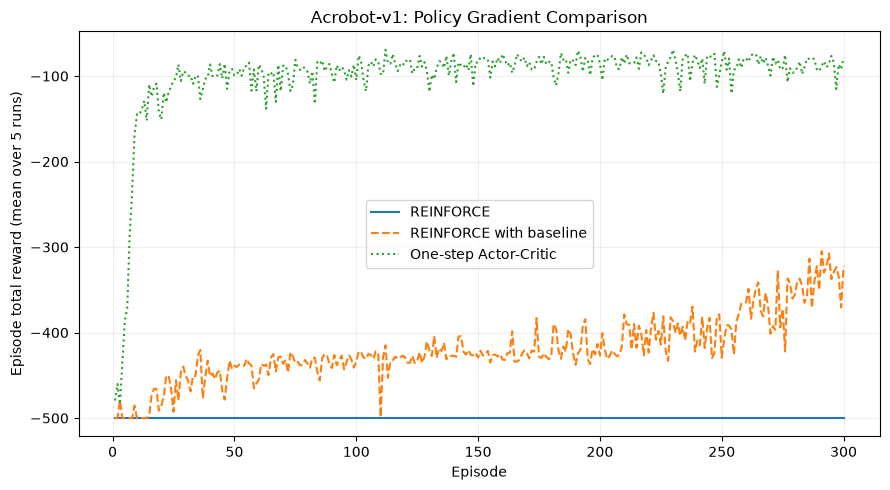

Mean reward over the final 50 episodes, averaged across seeds:

REINFORCE: -500.00
REINFORCE with baseline: -359.28
One-step Actor-Critic: -86.65


In [42]:
plot_environment_comparison(
    env_id="Acrobot-v1",
    results=acrobot_results,
)

print("Mean reward over the final 50 episodes, averaged across seeds:\n")

for name, runs in acrobot_results.items():
    final_mean = runs[:, -50:].mean()
    print(f"{name}: {final_mean:.2f}")

### Acrobot Results

The mean rewards over the final 50 episodes, averaged across five seeds,
were:

- REINFORCE: -500.00
- REINFORCE with baseline: -359.28
- One-step Actor-Critic: -86.65

One-step Actor-Critic improved rapidly and achieved the highest
final-window mean reward. REINFORCE with baseline improved more gradually.
Plain REINFORCE remained at -500 throughout the experiment.

These observations apply to the tested configurations and training budget.

## MountainCar Experiment

Compare all three algorithms using five independent seeds and
300 episodes per seed. Use the previously specified learning rates,
network architecture, and discount factor.

The agent must build momentum to reach the hilltop. Each step receives
a reward of -1, so higher episode returns indicate shorter episodes.
The environment has a 200-step time limit.


=== MountainCar-v0 | REINFORCE | Seed 1 ===
MountainCar-v0 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 250/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 300/300 | Mean reward over last 50 episodes: -200.00

=== MountainCar-v0 | REINFORCE | Seed 2 ===
MountainCar-v0 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -200.00
MountainCar-

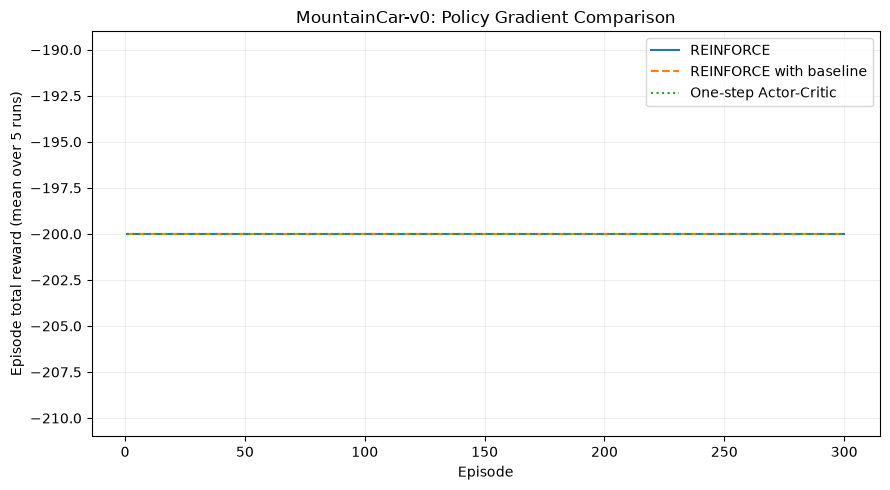


MountainCar final 50-episode results:

REINFORCE
Per-seed means: [-200. -200. -200. -200. -200.]
Mean across seeds: -200.00

REINFORCE with baseline
Per-seed means: [-200. -200. -200. -200. -200.]
Mean across seeds: -200.00

One-step Actor-Critic
Per-seed means: [-200. -200. -200. -200. -200.]
Mean across seeds: -200.00


In [43]:
mountaincar_results = run_environment_comparison(
    env_id="MountainCar-v0",
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
    gamma=GAMMA,
    learning_rates=LEARNING_RATES,
)

all_results["MountainCar-v0"] = mountaincar_results

plot_environment_comparison(
    env_id="MountainCar-v0",
    results=mountaincar_results,
)

print("\nMountainCar final 50-episode results:")

for name, runs in mountaincar_results.items():
    final_means = runs[:, -50:].mean(axis=1)

    print(f"\n{name}")
    print("Per-seed means:", np.round(final_means, 2))
    print(f"Mean across seeds: {final_means.mean():.2f}")

In [44]:
for name, runs in mountaincar_results.items():
    print(name)
    print("Best episode return:", runs.max())
    print(
        "Episodes with return above -200:",
        np.count_nonzero(runs > -200),
    )
    print()

REINFORCE
Best episode return: -200.0
Episodes with return above -200: 0

REINFORCE with baseline
Best episode return: -200.0
Episodes with return above -200: 0

One-step Actor-Critic
Best episode return: -200.0
Episodes with return above -200: 0



### MountainCar Training Budget Check

All three algorithms obtained a final-window mean reward of -200
across five seeds with 300 training episodes.

MountainCar provides a reward of -1 per step. Episodes that reach the
200-step limit therefore have the same total reward, providing limited
feedback about progress toward the goal.

Evaluate a longer training budget of 1,000 episodes using seed 1.
Keep the other settings unchanged. This single-seed experiment checks
whether additional training improves performance; it is not a replacement
for the five-seed comparison.


=== MountainCar-v0 | REINFORCE | Seed 1 ===
MountainCar-v0 | REINFORCE | Episode 50/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 100/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 150/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 200/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 250/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 300/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 350/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 400/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 450/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 500/1000 | Mean reward over last 50 episodes: -200.00
MountainCar-v0 | REINFORCE | Episode 550/1000 

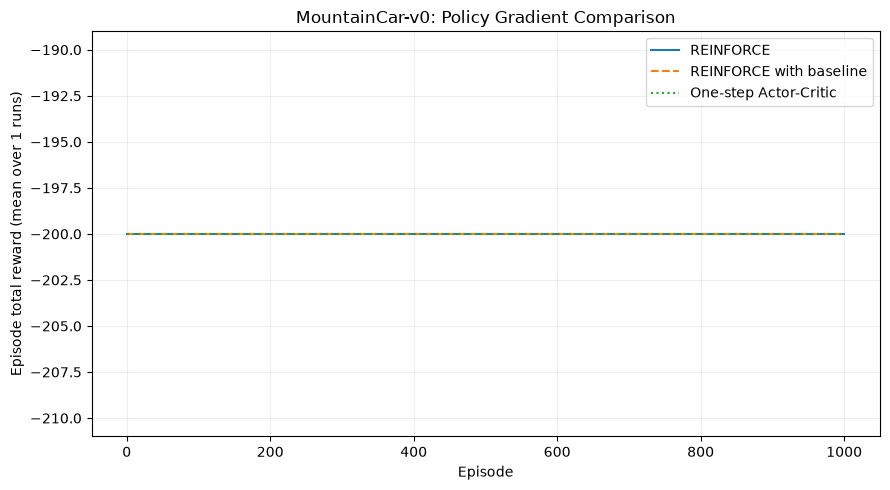


Training budget comparison for seed 1:

REINFORCE
300 episodes, final-window mean: -200.00
1000 episodes, final-window mean: -200.00
Best return during longer run: -200.00

REINFORCE with baseline
300 episodes, final-window mean: -200.00
1000 episodes, final-window mean: -200.00
Best return during longer run: -200.00

One-step Actor-Critic
300 episodes, final-window mean: -200.00
1000 episodes, final-window mean: -200.00
Best return during longer run: -200.00


In [45]:
mountaincar_long_results = run_environment_comparison(
    env_id="MountainCar-v0",
    seeds=[1],
    num_episodes=1000,
    gamma=GAMMA,
    learning_rates=LEARNING_RATES,
)

plot_environment_comparison(
    env_id="MountainCar-v0",
    results=mountaincar_long_results,
)

print("\nTraining budget comparison for seed 1:")

for name, runs in mountaincar_long_results.items():
    original_seed_index = SEEDS.index(1)
    original_final_mean = mountaincar_results[name][
        original_seed_index, -50:
    ].mean()

    print(f"\n{name}")
    print(f"300 episodes, final-window mean: {original_final_mean:.2f}")
    print(f"1000 episodes, final-window mean: {runs[0, -50:].mean():.2f}")
    print(f"Best return during longer run: {runs.max():.2f}")

### MountainCar Results

All three algorithms obtained a mean reward of -200 over the final
50 episodes, averaged across five seeds, with 300 training episodes.

A supplementary experiment increased the training budget to 1,000
episodes using seed 1. All three algorithms still obtained a best
episode return of -200, with no observed completion before the
200-step limit.

Increasing the training budget to this level did not improve performance
for the tested seed and configurations. The equal episode returns
provide limited feedback for distinguishing useful action sequences.

The main comparison retains the five-seed, 300-episode results.
The longer single-seed experiment is reported separately.

## FrozenLake Experiment

Compare all three algorithms using the default FrozenLake-v1 environment,
five independent seeds, and 300 episodes per seed.

Use the previously specified network architecture, learning rates,
and discount factor.

Under the default reward function, reaching the goal yields a reward
of 1; other transitions yield 0. Episode total reward is therefore
either 0 or 1, and its mean represents the observed success rate.


=== FrozenLake-v1 | REINFORCE | Seed 1 ===
FrozenLake-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: 0.02
FrozenLake-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: 0.00
FrozenLake-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: 0.00
FrozenLake-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: 0.00
FrozenLake-v1 | REINFORCE | Episode 250/300 | Mean reward over last 50 episodes: 0.04
FrozenLake-v1 | REINFORCE | Episode 300/300 | Mean reward over last 50 episodes: 0.00

=== FrozenLake-v1 | REINFORCE | Seed 2 ===
FrozenLake-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: 0.02
FrozenLake-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: 0.02
FrozenLake-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: 0.00
FrozenLake-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: 0.02
FrozenLake-v1 | REINFORCE | Episode 250/300 | Mean rew

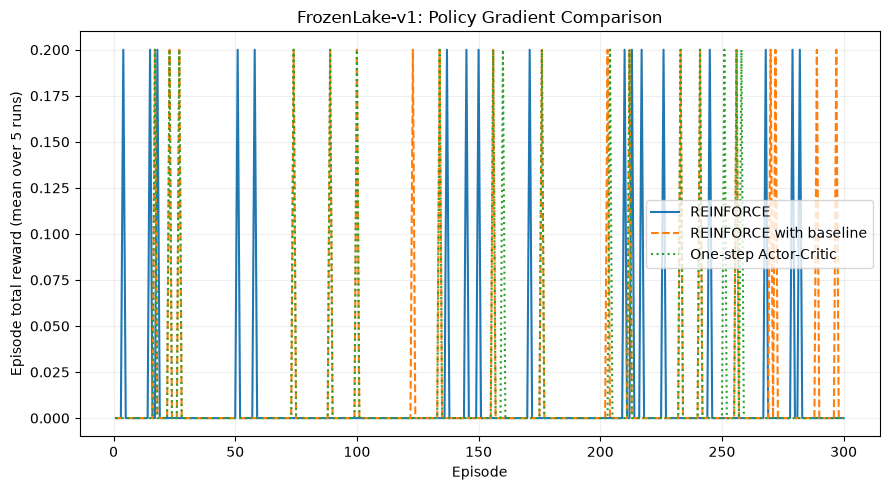


FrozenLake final 50-episode results:

REINFORCE
Per-seed success rates: [0.   0.   0.04 0.   0.02]
Mean success rate across seeds: 1.2%

REINFORCE with baseline
Per-seed success rates: [0.   0.02 0.04 0.04 0.  ]
Mean success rate across seeds: 2.0%

One-step Actor-Critic
Per-seed success rates: [0.   0.04 0.   0.02 0.  ]
Mean success rate across seeds: 1.2%


In [46]:
frozenlake_results = run_environment_comparison(
    env_id="FrozenLake-v1",
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
    gamma=GAMMA,
    learning_rates=LEARNING_RATES,
)

all_results["FrozenLake-v1"] = frozenlake_results

plot_environment_comparison(
    env_id="FrozenLake-v1",
    results=frozenlake_results,
)

print("\nFrozenLake final 50-episode results:")

for name, runs in frozenlake_results.items():
    final_means = runs[:, -50:].mean(axis=1)

    print(f"\n{name}")
    print("Per-seed success rates:", np.round(final_means, 3))
    print(
        "Mean success rate across seeds:",
        f"{final_means.mean():.1%}",
    )

### FrozenLake Results

The observed success rates over the final 50 episodes, averaged across
five seeds, were:

- REINFORCE: 1.2%
- REINFORCE with baseline: 2.0%
- One-step Actor-Critic: 1.2%

Successful episodes were rare, and the curves show no clear sustained
improvement under the tested configurations and training budget.

Each episode return is either 0 or 1. Averaging five runs produces
increments of 0.2 in the plotted curves.

The small final-window difference does not establish a reliable
advantage for the baseline variant.

## Blackjack Experiment

Compare all three algorithms using the default Blackjack-v1 environment,
five independent seeds, and 300 episodes per seed.

Encode the observation tuple by concatenating the one-hot encodings
of its three components. The resulting network input dimension is 45,
and the policy has two actions: stick and hit.

With the default reward settings, a win yields +1, a loss yields -1,
and a draw yields 0. Mean episode reward measures net outcome rather
than win rate.


=== Blackjack-v1 | REINFORCE | Seed 1 ===
Blackjack-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -0.58
Blackjack-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -0.42
Blackjack-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -0.30
Blackjack-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -0.32
Blackjack-v1 | REINFORCE | Episode 250/300 | Mean reward over last 50 episodes: -0.50
Blackjack-v1 | REINFORCE | Episode 300/300 | Mean reward over last 50 episodes: -0.32

=== Blackjack-v1 | REINFORCE | Seed 2 ===
Blackjack-v1 | REINFORCE | Episode 50/300 | Mean reward over last 50 episodes: -0.58
Blackjack-v1 | REINFORCE | Episode 100/300 | Mean reward over last 50 episodes: -0.54
Blackjack-v1 | REINFORCE | Episode 150/300 | Mean reward over last 50 episodes: -0.42
Blackjack-v1 | REINFORCE | Episode 200/300 | Mean reward over last 50 episodes: -0.18
Blackjack-v1 | REINFORCE | Episode 250/300 | Mean reward

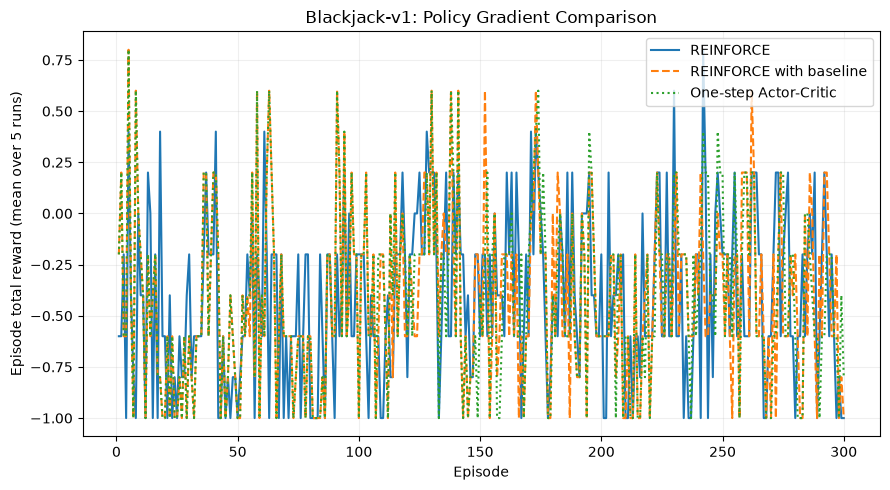


Blackjack final 50-episode results:

REINFORCE
Per-seed mean rewards: [-0.32 -0.5  -0.44 -0.3  -0.34]
Mean reward across seeds: -0.380

REINFORCE with baseline
Per-seed mean rewards: [-0.26 -0.6  -0.22 -0.48 -0.52]
Mean reward across seeds: -0.416

One-step Actor-Critic
Per-seed mean rewards: [-0.5  -0.36 -0.4  -0.4  -0.52]
Mean reward across seeds: -0.436


In [47]:
blackjack_results = run_environment_comparison(
    env_id="Blackjack-v1",
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
    gamma=GAMMA,
    learning_rates=LEARNING_RATES,
)

all_results["Blackjack-v1"] = blackjack_results

plot_environment_comparison(
    env_id="Blackjack-v1",
    results=blackjack_results,
)

print("\nBlackjack final 50-episode results:")

for name, runs in blackjack_results.items():
    final_means = runs[:, -50:].mean(axis=1)

    print(f"\n{name}")
    print("Per-seed mean rewards:", np.round(final_means, 3))
    print(f"Mean reward across seeds: {final_means.mean():.3f}")

### Blackjack Results

The mean rewards over the final 50 episodes, averaged across five seeds,
were:

- REINFORCE: -0.380
- REINFORCE with baseline: -0.416
- One-step Actor-Critic: -0.436

REINFORCE obtained the highest final-window mean reward under the tested
settings. However, the curves fluctuate substantially and show no clear
sustained improvement. These results do not establish a reliable ranking
of the algorithms.

In [48]:
from IPython.display import Markdown, display

algorithm_names = list(LEARNING_RATES)

table_lines = [
    "| Environment | " + " | ".join(algorithm_names) + " |",
    "| --- | " + " | ".join(["---:"] * len(algorithm_names)) + " |",
]

for env_id in ENV_IDS:
    values = []

    for name in algorithm_names:
        runs = all_results[env_id][name]

        assert runs.shape == (len(SEEDS), NUM_EPISODES)
        assert np.isfinite(runs).all()

        final_mean = runs[:, -50:].mean()
        values.append(f"{final_mean:.3f}")

    table_lines.append(
        "| " + env_id + " | " + " | ".join(values) + " |"
    )

display(Markdown(
    "### Final 50-Episode Mean Rewards\n\n"
    "Values are averaged across five independent training runs.\n\n"
    + "\n".join(table_lines)
))

### Final 50-Episode Mean Rewards

Values are averaged across five independent training runs.

| Environment | REINFORCE | REINFORCE with baseline | One-step Actor-Critic |
| --- | ---: | ---: | ---: |
| CartPole-v1 | 75.304 | 58.636 | 94.944 |
| Acrobot-v1 | -500.000 | -359.284 | -86.648 |
| MountainCar-v0 | -200.000 | -200.000 | -200.000 |
| FrozenLake-v1 | 0.012 | 0.020 | 0.012 |
| Blackjack-v1 | -0.380 | -0.416 | -0.436 |

## Discussion

Performance depended on the environment and the selected settings.
No algorithm achieved the highest final-window mean reward in every
environment.

One-step Actor-Critic obtained the highest final-window mean rewards
on CartPole and Acrobot. Its improvement was particularly clear on
Acrobot, where plain REINFORCE remained at -500.

All three algorithms remained at -200 on MountainCar. Increasing the
training budget to 1,000 episodes for seed 1 did not improve this result.

FrozenLake success rates remained low, with no clear sustained
improvement. Blackjack results were noisy, and the final-window
differences did not establish a reliable algorithm ranking.

The learned baseline did not consistently improve observed performance.
Its usefulness depends on value estimation and the selected learning
rates.

These experiments used five seeds and 300 episodes per main run.
Learning rates were not extensively tuned for each environment.
The results describe this experimental setup rather than general
algorithm superiority or convergence.

Reported rewards come from training episodes sampled from the policies.
Comparisons are made within each environment because reward scales differ.